# Calidad de la telemetría de la flota: limitación de inyección y régimen vigente (experimento E28)

En este cuaderno detectamos en qué horas y en qué periodos cada planta tuvo activado el control de exportación
(inyección cero), fijamos el **régimen vigente** de cada unidad (régimen B) y medimos cuánto cambia el pronóstico si se
modela con el histórico sin depurar (régimen A). Lo hacemos porque, con el control activo, el inversor maestro reduce
la producción hasta que su sensor de red marca cero cuando la producción supera al consumo del predio. En esas horas
la producción sigue al consumo y no al recurso solar, de modo que un modelo meteorológico del rendimiento aprendería
una relación falsa y se evaluaría contra algo que no puede pronosticar.

Trabajamos con la telemetría cruda de `datos/telemetria/` (potencia AC por fase, `gridpower` del sensor de red, tensión
y potencia por entrada MPPT y estado del inversor), con la irradiancia del satélite MSG o del análisis IFS de
`datos/meteo/` y con las constantes de cada planta de `datos/parametros/`, que solo leemos. La ablación procesa cada
unidad con las decisiones de su cuaderno por localidad (fuente de irradiancia, factor de nivel y kWp auditado), y por
eso este cuaderno se ejecuta después de ellos, en la etapa final de `tools/ejecutar_flota.py`. Una unidad cuya
localidad aún no registró esas decisiones queda fuera de la ablación, con su motivo.

El cuaderno deja las marcas horarias y diarias de la limitación por planta, la fecha de inicio del régimen B de cada
unidad, los parámetros calibrados de la regla de tensión, las figuras (PNG y PDF en `resultados/figuras/`, con sus
valores en `resultados/datos_figuras/`), las tablas con solo códigos en `resultados/regimenes/` y el resumen en la
clave `flota.recorte` de `resultados/resultados.json`. Ninguna marca se escribe en `datos/`, todo lo que decidimos usa
datos anteriores al corte del modelado (`config.FIN_MODELADO`), la regla de tensión se calibra solo con el periodo de
entrenamiento y la semilla es 37.

In [1]:
# Parámetros (papermill los reemplaza)
GUARDAR_FIGURAS = True         # exportar figuras a resultados/figuras
ABLACION = True                # medir el costo de no depurar (régimen A frente a B) con el SARIMAX E2-MOS

In [2]:
import os, sys, warnings
from pathlib import Path
if not Path("tfm").is_dir() and Path("../tfm").is_dir():
    os.chdir("..")     # copia ejecutada abierta desde notebooks/ejecutados: se trabaja desde notebooks/
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown as MarkdownIPython
def Markdown(texto):                  # cifras con coma decimal, como en el documento y las figuras
    return MarkdownIPython(gr.texto_es(texto))
def miles(n):                         # separador de miles con espacio: 12 345 (la coma sería decimal)
    return f"{int(n):,}".replace(",", " ")

from tfm import config, datos, recorte, nomenclatura as nom, graficos as gr, resultados as res, particiones as part

config.fijar_semilla()
config.crear_directorios()
gr.estilo()
pd.set_option("display.max_columns", 40, "display.width", 200)
DIR_SALIDA = config.DIR_RESULTADOS / "regimenes"
DIR_SALIDA.mkdir(parents=True, exist_ok=True)
INICIO, FIN = config.INICIO_DATOS, config.FIN_ANALISIS
CORTE = pd.Timestamp(config.FIN_MODELADO)                  # fecha local exclusiva
FIN_CALIBRACION = pd.Timestamp(config.PARTICIONES["validacion"][0])   # la calibración solo ve el entrenamiento

def fig(f, nombre, datos_=None):
    gr.guardar(f, nombre, GUARDAR_FIGURAS, datos_)
    plt.show()
    plt.close(f)

display(Markdown(f"Corte del modelado: **{config.FIN_MODELADO}** (exclusivo). Particiones: {config.PARTICIONES}. "
                 f"La calibración de la regla de tensión usa los días anteriores al {FIN_CALIBRACION:%Y-%m-%d}."))

Corte del modelado: **2026-11-01** (exclusivo). Particiones: {'entrenamiento': ('2024-01-01', '2026-06-30'), 'validacion': ('2026-07-01', '2026-08-31'), 'prueba': ('2026-09-01', '2026-10-31'), 'vivo': ('2026-11-01', '2026-12-31')}. La calibración de la regla de tensión usa los días anteriores al 2026-07-01.

## 1. Flota del documento y sensor de red de cada planta

La flota del documento son las plantas con datos antes del fin de septiembre de 2026 (`config.ALTA_MAXIMA_FLOTA`).
SolaX publica la potencia de intercambio con la red como `gridpower` del inversor que tiene conectado el sensor (la
pinza amperimétrica o el medidor); en una planta de varios inversores, el sensor mide el intercambio de toda la
planta. Un inversor cuyo `gridpower` es cero exacto en casi todas las lecturas no tiene sensor en la plataforma.

In [3]:
tabla = nom.tabla()
grupos = datos.plantas_grupos()
alta = tabla.groupby("planta")["primer_dato"].min()
plantas = (tabla.drop_duplicates("planta")[["planta", "plantuuid"]].merge(grupos, on="plantuuid", how="left")
           .set_index("planta").sort_index())
plantas["primer_dato"] = pd.to_datetime(alta).dt.tz_convert(config.ZONA).dt.date
limite = pd.Timestamp(config.ALTA_MAXIMA_FLOTA).date()
plantas["en_documento"] = [d <= limite for d in plantas["primer_dato"]]
plantas["inversores"] = tabla.groupby("planta").size()
FLOTA = plantas[plantas["en_documento"] & plantas["grupo"].notna()]
display(plantas.drop(columns="plantuuid"))
display(Markdown(f"**Flota del documento:** {len(FLOTA)} plantas y {int(FLOTA['inversores'].sum())} inversores. "
                 f"Fuera del documento (alta posterior o sin grupo): {', '.join(plantas.index[~plantas.index.isin(FLOTA.index)])}."))

,grupo,primer_dato,en_documento,inversores
planta,,,,
P01,G01,2025-04-27,True,2
P02,G03,2025-02-13,True,2
P03,G03,2025-10-28,True,3
P04,G02,2025-01-27,True,2
P05,G06,2025-02-28,True,1
P06,G08,2025-03-02,True,3
P07,G01,2025-05-30,True,1
P08,G04,2025-06-24,True,1
P09,G09,2025-07-08,True,1


**Flota del documento:** 23 plantas y 37 inversores. Fuera del documento (alta posterior o sin grupo): P24, P25, P26.

## 2. Marca del sensor de red y régimen vigente de cada planta

Consideramos que una lectura de 5 minutos con producción (potencia AC de la planta mayor que el 5 % de su percentil 99
de 9 a 15 h) está **en cero** si |red| ≤ 2 % de ese percentil y no es un cero exacto. Un día está **limitado** si la
mediana móvil centrada de 7 días de su fracción de lecturas en cero (de 8 a 15 h, en días con al menos 20 lecturas) es
de 0,5 o más, y los días limitados definen los periodos. Una hora está **recortada** si al menos la mitad de sus
lecturas están en cero, en cualquier día, porque con el control activo el inversor solo recorta cuando la producción
supera al consumo y fuera de los días limitados quedan horas sueltas recortadas (limitación parcial).

El **régimen vigente (B)** empieza después del último día limitado antes del corte, en el primer día que muestra por sí
mismo inyección libre, es decir, cuya propia fracción de lecturas en cero es menor que 0,25, la mitad del umbral.
Dejamos fuera los días intermedios porque la mediana centrada se retrasa hasta tres días en la transición y un día
estrangulado hasta casi no producir (un domingo con consumo mínimo) no tiene fracción propia. Si alguno de los últimos
7 días antes del corte está limitado, la planta queda **limitada al corte** y fuera del régimen B, y si el régimen B
tiene menos de 28 días la unidad solo sirve para el experimento de suficiencia y el arranque en frío.

Descartamos otras opciones por razones concretas. Clasificar por meses, como en el experimento E27, no da la fecha
exacta del cambio y mezcla días limitados y libres. Exigir la red en cero en todas las lecturas sería demasiado
estricto, ya que aun con el control activo la red se aparta de cero unos minutos cuando el consumo cambia de golpe. Un
umbral absoluto en W no es comparable entre plantas de 3 y 200 kWp, mientras que el 2 % del percentil 99 sí lo es.
Marcar horas solo dentro de los días limitados dejaría en el régimen B la limitación parcial que cuantificamos abajo, y
empezar el régimen B el día siguiente al último día limitado metería en él los días de la transición, que todavía
están limitados o estrangulados.

In [4]:
LECT, MARCAS, DIAS, HORAS, REG = {}, {}, {}, {}, {}
EVENTOS = {}                 # por grupo: lo que declaro el instalador (telemetry.plantas_eventos)
filas = []
for planta, r in FLOTA.iterrows():
    if r.grupo not in EVENTOS:
        EVENTOS[r.grupo] = datos.constantes(r.grupo)["eventos"]
    lect = recorte.lecturas_planta(r.grupo, r.plantuuid, INICIO, FIN)
    m = recorte.marcas_sensor(lect)
    d = recorte.diario(m) if lect["con_sensor"] else None
    h = recorte.horario(m, d if d is not None else pd.DataFrame())
    LECT[planta], MARCAS[planta], DIAS[planta], HORAS[planta] = lect, m, d, h
    REG[planta] = recorte.regimen_vigente(d, CORTE, instalador=recorte.instalador_planta(EVENTOS[r.grupo], r.plantuuid))
    # Días entre el último día limitado y el inicio del régimen B (transición aun limitada o sin fracción propia)
    transicion = (int((REG[planta]["inicio_b"] - REG[planta]["ultimo_dia_limitado"]).days) - 1
                  if REG[planta].get("inicio_b") is not None and REG[planta].get("ultimo_dia_limitado") is not None else None)
    antes = h.index < pd.Timestamp(CORTE, tz=config.ZONA)
    # Dentro del régimen B (desde el fin de la limitación; todo lo anterior al corte si nunca limitó): horas con producción
    # y horas recortadas sueltas, la limitación parcial que queda después del último día limitado
    if lect["con_sensor"] and REG[planta]["estado"] in ("liberada", "liberada hace poco", "nunca limitada"):
        ini_b = REG[planta].get("inicio_b")
        en_b = antes & ((h.index >= pd.Timestamp(ini_b, tz=config.ZONA)) if ini_b is not None else True)
        horas_b = int((en_b & (h["lecturas_cero"] >= 6)).sum())
        recortadas_b = int((en_b & h["recortada"]).sum())
    else:
        horas_b, recortadas_b = None, None
    filas.append({"planta": planta, "grupo": r.grupo, "sensor": lect["con_sensor"] or "sin sensor",
                  "dias_con_marca": None if d is None else int((d.index < CORTE).sum()),
                  "dias_limitados": None if d is None else int(d.loc[d.index < CORTE, "limitado"].sum()),
                  "horas_recortadas": int(h.loc[antes, "recortada"].sum()) if lect["con_sensor"] else None,
                  "horas_produccion_b": horas_b, "horas_recortadas_b": recortadas_b, "dias_transicion": transicion,
                  "filas_desfase_desconocido": lect["desfase_desconocido"],
                  **{k: (str(v.date()) if hasattr(v, "date") else v) for k, v in REG[planta].items()}})
RESUMEN = pd.DataFrame(filas).set_index("planta")
RESUMEN.to_csv(DIR_SALIDA / "regimen_por_planta.csv")
display(RESUMEN)
conteo = RESUMEN["estado"].value_counts()
con_transicion = RESUMEN["dias_transicion"].dropna()
con_transicion = con_transicion[con_transicion > 0]
display(Markdown("**Estado al corte:** " + "; ".join(f"{k}: {v}" for k, v in conteo.items()) + ". "
                 + (f"En {len(con_transicion)} plantas el régimen B no empieza el día siguiente al último día limitado, porque los "
                    "días de la transición seguían limitados o casi sin producción: "
                    + ", ".join(f"{p} ({int(v)} {'día' if int(v) == 1 else 'días'})" for p, v in con_transicion.items()) + "."
                    if len(con_transicion) else "")))

,grupo,sensor,dias_con_marca,dias_limitados,horas_recortadas,horas_produccion_b,horas_recortadas_b,dias_transicion,filas_desfase_desconocido,estado,inicio_b,ultimo_dia_limitado,dias_b,origen,fin_reparacion
planta,,,,,,,,,,,,,,,
P01,G01,sin sensor,NaN,NaN,NaN,NaN,NaN,NaN,0,sin sensor,NaN,NaN,NaN,telemetria,NaN
P02,G03,P02I0202,581.0,155.0,1417.0,4329.0,35.0,0.0,0,liberada,2025-08-30,2025-08-29,428.0,telemetria,NaN
P03,G03,P03I0303,336.0,89.0,973.0,909.0,10.0,2.0,0,liberada,2026-08-07,2026-08-04,86.0,telemetria,NaN
P04,G02,P04I0202,619.0,147.0,1296.0,3909.0,63.0,15.0,0,liberada,2025-09-17,2025-09-01,410.0,telemetria,2025-09-17
P05,G06,P05I0101,451.0,308.0,2376.0,1506.0,53.0,1.0,0,liberada,2026-06-10,2026-06-08,144.0,telemetria,NaN
P06,G08,P06I0203,544.0,493.0,4192.0,NaN,NaN,NaN,0,limitada al corte,NaN,2026-10-31,0.0,instalador,NaN
P07,G01,P07I0101,481.0,134.0,1928.0,2745.0,134.0,0.0,0,liberada,2026-02-27,2026-02-26,247.0,telemetria,NaN
P08,G04,P08I0101,434.0,0.0,1.0,4250.0,1.0,NaN,0,nunca limitada,NaN,NaN,483.0,telemetria,NaN
P09,G09,P09I0101,274.0,0.0,0.0,2741.0,0.0,NaN,0,nunca limitada,NaN,NaN,480.0,telemetria,NaN


**Estado al corte:** liberada: 10; limitada al corte: 6; nunca limitada: 4; liberada hace poco: 2; sin sensor: 1. En 7 plantas el régimen B no empieza el día siguiente al último día limitado, porque los días de la transición seguían limitados o casi sin producción: P03 (2 días), P04 (15 días), P05 (1 día), P13 (2 días), P14 (2 días), P17 (1 día), P18 (3 días).

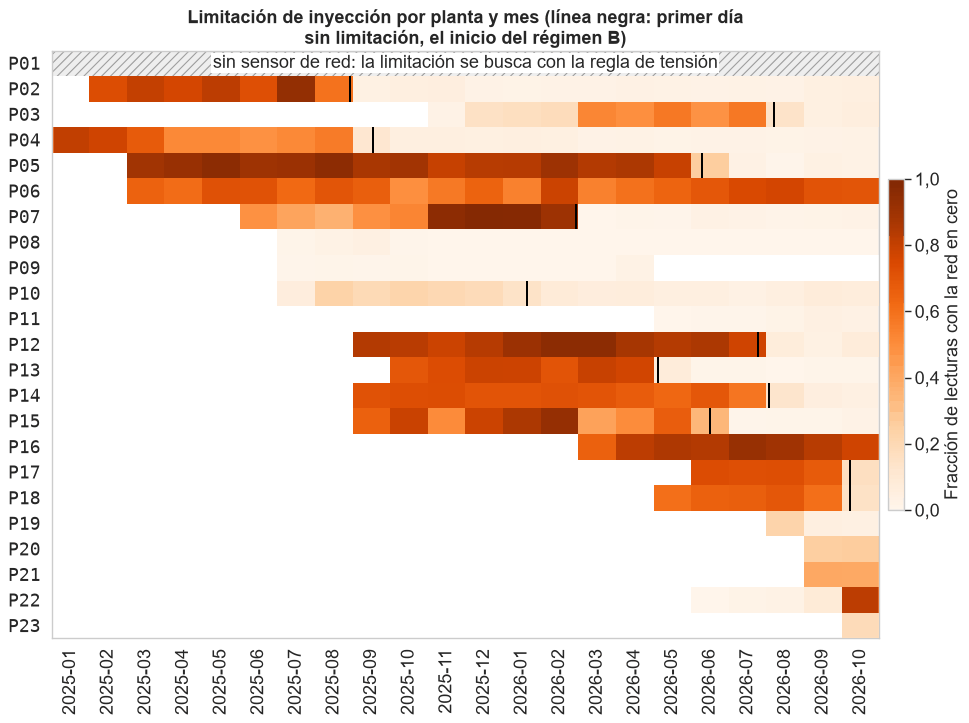

**Plantas sin sensor de red** (1): P01. En la figura van rayadas porque no miden la potencia de la red; en ellas la limitación se busca con la regla de tensión de la sección 4.

In [5]:
# Línea de tiempo mensual de la flota: fracción de lecturas en cero de 8 a 15 h (plantas con sensor)
from matplotlib.patches import Rectangle
mensual = {}
for planta, d in DIAS.items():
    if d is None or d.empty:
        continue
    s = d.loc[d.index < CORTE, "fraccion_cero"]
    mensual[planta] = s.groupby(s.index.to_period("M")).mean()
M = pd.DataFrame(mensual).T
M.columns = [str(c) for c in M.columns]
# Las plantas sin sensor de red van en la figura con una fila rayada: no miden la potencia de la red
SIN_SENSOR = [p for p, l in LECT.items() if not l["con_sensor"]]
M = pd.concat([M, pd.DataFrame(np.nan, index=SIN_SENSOR, columns=M.columns)]).sort_index()
f, ax = plt.subplots(figsize=(12, 0.32 * len(M) + 1.6))
im = ax.imshow(M.to_numpy(dtype=float), aspect="auto", cmap="Oranges", vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(M)), M.index, fontsize=8)
ax.set_xticks(range(len(M.columns)), M.columns, rotation=90, fontsize=7)
ax.grid(False)                      # la cuadrícula del estilo cortaba las marcas
for i, planta in enumerate(M.index):
    if planta in SIN_SENSOR:
        ax.add_patch(Rectangle((-0.5, i - 0.5), len(M.columns), 1, facecolor="#EEEEEE", edgecolor="#9E9E9E", hatch="///", lw=0))
        ax.text((len(M.columns) - 1) / 2, i, "sin sensor de red: la limitación se busca con la regla de tensión", ha="center",
                va="center", bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
        continue
    ini_b = REG[planta].get("inicio_b")
    if ini_b is not None and str(ini_b.to_period("M")) in M.columns:
        # La marca va en su día dentro del mes: cada celda va del día 1 al último del mes
        j = list(M.columns).index(str(ini_b.to_period("M")))
        x = j - 0.5 + (ini_b.day - 1) / ini_b.days_in_month
        ax.plot([x, x], [i - 0.5, i + 0.5], color="black", ls="-", lw=1.8, solid_capstyle="butt")   # ls fijo: el estilo alterna tipos de línea
cb = f.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
cb.set_label("Fracción de lecturas con la red en cero", fontsize=8)
ax.set_title("Limitación de inyección por planta y mes (línea negra: primer día sin limitación, el inicio del régimen B)")
fig(f, "flota_recorte_mensual", M)
if SIN_SENSOR:
    display(Markdown(f"**Plantas sin sensor de red** ({len(SIN_SENSOR)}): {', '.join(SIN_SENSOR)}. En la figura van "
                     "rayadas porque no miden la potencia de la red; en ellas la limitación se busca con la regla de "
                     "tensión de la sección 4."))

## 3. Firma física del recorte

Si la red queda en cero porque el inversor recorta, la potencia debe estar muy por debajo de la que el sol permite y
el punto de operación debe alejarse del de máxima potencia: para entregar menos con la misma irradiancia, el inversor
sube la tensión del generador hacia la de circuito abierto. Se comparan, de 10 a 13 h y por planta con sensor, la
potencia AC relativa a su percentil 99 y la tensión de operación relativa a su referencia, según la red esté en
cero o exportando.

In [6]:
filas = []
for planta, lect in LECT.items():
    if not lect["con_sensor"]:
        continue
    th = recorte.tension_horaria(lect)
    h = HORAS[planta]
    for codigo in lect["ac"].columns:
        if ("v_rel", codigo) not in th:
            continue
        x = pd.DataFrame({"v_rel": th[("v_rel", codigo)], "p_rel": th[("p_rel", codigo)], "frac_cero": h["frac_cero"]}).dropna()
        hora = x.index.tz_convert(config.ZONA).hour
        x = x[(hora >= 11) & (hora <= 14) & (x.index < pd.Timestamp(CORTE, tz=config.ZONA))]
        cero, libre = x[x["frac_cero"] >= 0.5], x[x["frac_cero"] <= 0.1]
        if len(cero) >= 20 and len(libre) >= 20:
            filas.append({"inversor": codigo, "horas_en_cero": len(cero), "horas_libres": len(libre),
                          "p_rel_en_cero": cero["p_rel"].median(), "p_rel_libre": libre["p_rel"].median(),
                          "v_rel_en_cero": cero["v_rel"].median(), "v_rel_libre": libre["v_rel"].median()})
FIRMA = pd.DataFrame(filas).set_index("inversor")
display(FIRMA.round(3))
if len(FIRMA):
    display(Markdown(
        f"En las horas con la red en cero, la potencia mediana queda en el {100 * FIRMA['p_rel_en_cero'].median():.0f} % "
        f"de su percentil 99 (frente al {100 * FIRMA['p_rel_libre'].median():.0f} % cuando la red no está en cero), y la tensión "
        f"de operación sube un {100 * (FIRMA['v_rel_en_cero'] / FIRMA['v_rel_libre']).median() - 100:.0f} % (mediana de "
        f"{len(FIRMA)} inversores). Es la firma del recorte: el inversor se aparta del punto de máxima potencia."))
FIRMA.to_csv(DIR_SALIDA / "firma_recorte.csv")

,horas_en_cero,horas_libres,p_rel_en_cero,p_rel_libre,v_rel_en_cero,v_rel_libre
inversor,,,,,,
P02I0102,512,1570,0.473,0.776,1.238,1.014
P02I0202,565,1577,0.244,0.797,1.187,1.015
P03I0303,324,342,0.253,0.817,1.175,1.019
P03I0203,324,343,0.318,0.811,1.167,1.017
P03I0103,324,342,0.317,0.800,1.150,1.017
P05I0101,1040,561,0.283,0.794,1.138,1.012
P06I0103,1703,149,0.305,0.485,1.079,0.996
P06I0203,1705,105,0.241,0.383,1.081,0.995
P06I0303,1109,52,0.243,0.414,1.086,0.977


En las horas con la red en cero, la potencia mediana queda en el 31 % de su percentil 99 (frente al 70 % cuando la red no está en cero), y la tensión de operación sube un 13 % (mediana de 24 inversores). Es la firma del recorte: el inversor se aparta del punto de máxima potencia.

### Horas recortadas dentro del régimen B: recorte o coincidencia

Dentro del régimen B quedan horas sueltas con la red en cero. Pueden ser recorte (el control sigue activo y actúa
cuando la producción supera al consumo) o coincidencia (la producción iguala por azar al consumo, algo más probable
con poca producción, al amanecer y al atardecer). La diferencia está en la producción: el recorte la deja por debajo
de la que permite el sol y la coincidencia no. Para cada hora marcada se divide la potencia de la planta por la
mediana de las horas no marcadas del mismo régimen con la misma hora local y la misma irradiancia (tramos de 50 W/m²
del GHI del grupo, del satélite MSG o del análisis IFS). Un cociente de 0,85 o más es la producción típica.

C:\Users\leons\AppData\Local\Temp\ipykernel_14412\1124036633.py:24: RuntimeWarning: invalid value encountered in divide
  t["cociente"] = t["p_rel"].to_numpy() / tipica.reindex(pd.MultiIndex.from_arrays([t["hora"], t["tramo"]])).to_numpy()


C:\Users\leons\AppData\Local\Temp\ipykernel_14412\1124036633.py:24: RuntimeWarning: invalid value encountered in divide
  t["cociente"] = t["p_rel"].to_numpy() / tipica.reindex(pd.MultiIndex.from_arrays([t["hora"], t["tramo"]])).to_numpy()


C:\Users\leons\AppData\Local\Temp\ipykernel_14412\1124036633.py:24: RuntimeWarning: invalid value encountered in divide
  t["cociente"] = t["p_rel"].to_numpy() / tipica.reindex(pd.MultiIndex.from_arrays([t["hora"], t["tramo"]])).to_numpy()


,horas,cociente_mediano,ghi_mediano,pct_tipica
hora,,,,
6,140,0.93,98.58,60.71
7,33,0.65,312.00,39.39
8,17,0.43,525.25,23.53
9,12,0.45,742.13,8.33
10,15,0.49,894.50,13.33
11,15,0.38,950.50,20.00
12,18,0.57,752.88,27.78
13,12,0.62,631.88,16.67
14,21,0.47,449.00,9.52


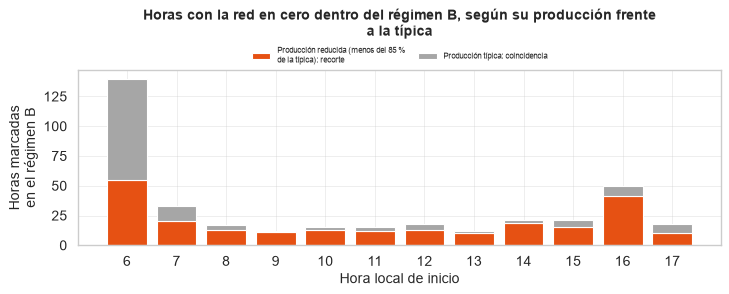

De las 372 horas marcadas dentro del régimen B con irradiancia y producción (15 plantas), el 38 % tiene la producción típica de su hora e irradiancia: son coincidencias. La hora con más marcas es la de las 6 h (140 horas, cociente mediano de 0,93). De 8 a 14 h el cociente mediano es de 0,47 y el 83 % de las horas produce menos de lo típico: ahí domina el recorte.

Por eso excluimos todas las horas marcadas. Excluir una coincidencia solo quita una hora con la producción normal y no sesga el objetivo; conservar una hora recortada sí lo sesga hacia abajo. Exigir además que la producción quede por debajo de la típica obligaría a estimar la producción esperada de cada hora, que es justamente lo que se pronostica.

In [7]:
# Horas marcadas dentro del régimen B: producción de la planta frente a la típica con la misma hora e irradiancia
from tfm import solar
CLARIDAD_B, marcadas_b = {}, []
for planta, lect in LECT.items():
    reg_ = REG[planta]
    if not lect["con_sensor"] or reg_["estado"] not in ("liberada", "liberada hace poco", "nunca limitada"):
        continue
    g = FLOTA.loc[planta, "grupo"]
    h, m = HORAS[planta], MARCAS[planta]
    ini_b = reg_["inicio_b"] if reg_.get("inicio_b") is not None else DIAS[planta].index.min()
    dia_h = (h.index - pd.Timedelta(seconds=1)).tz_convert(config.ZONA).tz_localize(None).normalize()
    en_b = np.asarray((dia_h >= ini_b) & (dia_h < CORTE))
    p_rel = (m["ac"] / m.attrs["p99_w"]).resample("1h", closed="right", label="right").mean().reindex(h.index)
    if g not in CLARIDAD_B:
        CLARIDAD_B[g] = recorte.claridad_grupo(g, INICIO, FIN)
    punto = datos.constantes(g)["grupo"].iloc[0]
    lugar = solar.ubicacion(punto.latitude, punto.longitude, punto.elevacion)
    ghi = CLARIDAD_B[g].reindex(h.index) * solar.cielo_despejado(h.index, lugar, pd.Timedelta("30min"))["ghi_cs"]
    t = pd.DataFrame({"p_rel": p_rel.to_numpy(), "ghi": ghi.to_numpy(), "recortada": h["recortada"].to_numpy(),
                      "hora": (h.index - pd.Timedelta("30min")).tz_convert(config.ZONA).hour}, index=h.index)[en_b]
    t = t[(t["ghi"] > 20) & t["p_rel"].notna()]
    t["tramo"] = (t["ghi"] // 50).astype(int)
    tipica = t[~t["recortada"]].groupby(["hora", "tramo"])["p_rel"].median()
    t["cociente"] = t["p_rel"].to_numpy() / tipica.reindex(pd.MultiIndex.from_arrays([t["hora"], t["tramo"]])).to_numpy()
    marcadas_b.append(t[t["recortada"]].assign(planta=planta))
MB = pd.concat(marcadas_b).dropna(subset=["cociente"]) if marcadas_b else pd.DataFrame(columns=["hora", "cociente", "ghi", "planta"])
TIPICA = 0.85                   # cociente desde el que la producción de la hora es la típica (coincidencia)
POR_HORA_B = MB.groupby("hora").agg(horas=("cociente", "size"), cociente_mediano=("cociente", "median"),
                                    ghi_mediano=("ghi", "median"), pct_tipica=("cociente", lambda s: 100 * (s >= TIPICA).mean()))
display(POR_HORA_B.round(2))
COINCIDENCIA = {}
if len(MB):
    tipo = np.where(MB["cociente"] >= TIPICA, "tipica", "reducida")
    barras = MB.assign(tipo=tipo).groupby(["hora", "tipo"]).size().unstack(fill_value=0).reindex(columns=["reducida", "tipica"], fill_value=0)
    f, ax = plt.subplots(figsize=(9, 3.6))
    ax.bar(barras.index, barras["reducida"], color=config.PALETA[0], label="Producción reducida (menos del 85 % de la típica): recorte")
    ax.bar(barras.index, barras["tipica"], bottom=barras["reducida"], color="#A6A6A6", label="Producción típica: coincidencia")
    ax.set_xticks(barras.index)
    ax.set_xlabel("Hora local de inicio")
    ax.set_ylabel("Horas marcadas en el régimen B")
    ax.legend(loc="upper right", frameon=False)
    ax.set_title("Horas con la red en cero dentro del régimen B, según su producción frente a la típica")
    fig(f, "flota_recortadas_b_por_hora", POR_HORA_B)
    centrales = MB["hora"].between(8, 14)
    hora_max = int(POR_HORA_B["horas"].idxmax())
    COINCIDENCIA = {
        "recortadas_b_evaluadas": int(len(MB)), "recortadas_b_plantas": int(MB["planta"].nunique()),
        "recortadas_b_pct_tipica": float(100 * (MB["cociente"] >= TIPICA).mean()),
        "recortadas_b_hora_max": hora_max, "recortadas_b_horas_hora_max": int(POR_HORA_B.loc[hora_max, "horas"]),
        "recortadas_b_cociente_hora_max": float(POR_HORA_B.loc[hora_max, "cociente_mediano"]),
        "recortadas_b_cociente_centrales": float(MB.loc[centrales, "cociente"].median()) if centrales.any() else None,
        "recortadas_b_pct_reducida_centrales": float(100 * (MB.loc[centrales, "cociente"] < TIPICA).mean()) if centrales.any() else None}
    c = COINCIDENCIA
    display(Markdown(
        f"De las {c['recortadas_b_evaluadas']} horas marcadas dentro del régimen B con irradiancia y producción "
        f"({c['recortadas_b_plantas']} plantas), el {c['recortadas_b_pct_tipica']:.0f} % tiene la producción típica de su hora e "
        f"irradiancia: son coincidencias. La hora con más marcas es la de las {hora_max} h ({c['recortadas_b_horas_hora_max']} horas, "
        f"cociente mediano de {c['recortadas_b_cociente_hora_max']:.2f}). "
        + (f"De 8 a 14 h el cociente mediano es de {c['recortadas_b_cociente_centrales']:.2f} y el "
           f"{c['recortadas_b_pct_reducida_centrales']:.0f} % de las horas produce menos de lo típico: ahí domina el recorte."
           if c["recortadas_b_cociente_centrales"] is not None else "")
        + "\n\nPor eso excluimos todas las horas marcadas. Excluir una coincidencia solo quita una hora con la producción "
        "normal y no sesga el objetivo; conservar una hora recortada sí lo sesga hacia abajo. Exigir además que la producción "
        "quede por debajo de la típica obligaría a estimar la producción esperada de cada hora, que es justamente lo que se pronostica."))

## 4. Regla de tensión para las plantas sin sensor: calibración contra el sensor

Para las plantas sin sensor usamos la firma eléctrica del recorte. Una hora está recortada si la tensión de operación
es al menos (1 + δ) veces su referencia, la potencia está por debajo de κ veces su percentil 99 y la hora es despejada
(claridad ≥ c, donde la claridad es GHI / GHI de cielo despejado de la fuente de detección). Exigimos la claridad para
no confundir una hora nublada, con potencia baja y tensión normal o algo más alta por la menor temperatura del módulo,
con un recorte.

Aplicamos la regla solo en las horas que empiezan de las 9 a las 14 (`recorte.HORAS_TENSION`), las mismas con que la
calibramos, porque antes de las 9 y después de las 15 el módulo frío y el sol bajo dan la misma firma (tensión alta y
potencia baja) sin que haya recorte, como muestra la tabla de precisión por hora de esta sección. Probamos calibrar en
esa ventana y aplicar la regla todo el día, y la descartamos porque en la planta sin sensor marcaba como recortadas casi
todas las mañanas despejadas desde marzo de 2026 (el 52 a 56 % de las horas de las 6 y las 7) y dejaba incompletos sus
días. El costo de la ventana es que el recorte real fuera de ella no se detecta sin sensor, y por eso informamos cuánto
es.

Para calibrar elegimos la combinación (δ, κ, c) con mayor F1 frente a la marca del sensor en las horas de la ventana
**del periodo de entrenamiento** de las plantas con sensor. Informamos además su precisión y su exhaustividad fuera de
la calibración (validación y prueba), que es la estimación honesta de su desempeño.

In [8]:
CLARIDAD = {}
partes = []
for planta, lect in LECT.items():
    if not lect["con_sensor"]:
        continue
    g = FLOTA.loc[planta, "grupo"]
    if g not in CLARIDAD:
        CLARIDAD[g] = recorte.claridad_grupo(g, INICIO, FIN)
    th = recorte.tension_horaria(lect)
    for codigo in lect["ac"].columns:
        if ("v_rel", codigo) not in th:
            continue
        x = pd.DataFrame({"v_rel": th[("v_rel", codigo)], "p_rel": th[("p_rel", codigo)],
                          "claridad": CLARIDAD[g].reindex(th.index), "recortada": HORAS[planta]["recortada"].reindex(th.index)})
        x["inversor"], x["planta"] = codigo, planta
        partes.append(x)
TODAS_H = pd.concat(partes).dropna(subset=["v_rel", "p_rel", "claridad", "recortada"])
CAL = TODAS_H[recorte.en_ventana_tension(TODAS_H.index)]
dia_cal = CAL.index.tz_convert(config.ZONA).tz_localize(None).normalize()
EN_CALIB = dia_cal < FIN_CALIBRACION
FUERA = (dia_cal >= FIN_CALIBRACION) & (dia_cal < CORTE)
rej = recorte.calibrar_tension(CAL.loc[EN_CALIB, "v_rel"].reset_index(drop=True), CAL.loc[EN_CALIB, "p_rel"].reset_index(drop=True),
                               CAL.loc[EN_CALIB, "claridad"].reset_index(drop=True), CAL.loc[EN_CALIB, "recortada"].astype(bool).reset_index(drop=True))
display(rej.head(10).round(3))
MEJOR = rej.iloc[0]
PARAM = {"delta": float(MEJOR.delta), "kappa": float(MEJOR.kappa), "claridad_minima": float(MEJOR.claridad_minima)}
fuera = recorte.calibrar_tension(CAL.loc[FUERA, "v_rel"].reset_index(drop=True), CAL.loc[FUERA, "p_rel"].reset_index(drop=True),
                                 CAL.loc[FUERA, "claridad"].reset_index(drop=True), CAL.loc[FUERA, "recortada"].astype(bool).reset_index(drop=True),
                                 deltas=(PARAM["delta"],), kappas=(PARAM["kappa"],), claridades=(PARAM["claridad_minima"],)).iloc[0]
display(Markdown(
    f"**Regla elegida:** δ = {PARAM['delta']:.2f}, κ = {PARAM['kappa']:.2f}, claridad ≥ {PARAM['claridad_minima']:.2f}. "
    f"En la calibración (entrenamiento, {miles(MEJOR.horas)} horas, {miles(MEJOR.recortadas_sensor)} recortadas según el sensor): "
    f"precisión {MEJOR.precision:.2f}, exhaustividad {MEJOR.exhaustividad:.2f}, F1 {MEJOR.f1:.2f}. "
    f"Fuera de la calibración (validación y prueba, {miles(fuera.horas)} horas): precisión {fuera.precision:.2f}, "
    f"exhaustividad {fuera.exhaustividad:.2f}, F1 {fuera.f1:.2f}."))
if any(abs(PARAM[k] - recorte.PARAMETROS_TENSION[k]) > 1e-9 for k in PARAM):
    display(Markdown(f"**Atención:** `tfm/recorte.PARAMETROS_TENSION` vale {recorte.PARAMETROS_TENSION}; hay que fijarlo en {PARAM} "
                     "antes de ejecutar los cuadernos por localidad."))
rej.to_csv(DIR_SALIDA / "calibracion_regla_tension.csv", index=False)

# Evidencia de la ventana: precisión y exhaustividad por hora local de inicio de la firma con los parámetros elegidos,
# aplicada a todas las horas (sin ventana), en todo el periodo hasta el corte
dia_t = TODAS_H.index.tz_convert(config.ZONA).tz_localize(None).normalize()
T_H = TODAS_H[dia_t < CORTE].copy()
T_H["regla"] = ((T_H["v_rel"] >= 1 + PARAM["delta"]) & (T_H["p_rel"] < PARAM["kappa"])
                & (T_H["claridad"] >= PARAM["claridad_minima"])).to_numpy()   # la firma sin ventana
T_H["sensor"] = T_H["recortada"].astype(bool)
T_H["hora_inicio"] = (T_H.index - pd.Timedelta("30min")).tz_convert(config.ZONA).hour
POR_HORA = T_H.groupby("hora_inicio").agg(horas=("sensor", "size"), pct_recortadas_sensor=("sensor", "mean"))
POR_HORA["precision"] = T_H[T_H["regla"]].groupby("hora_inicio")["sensor"].mean()
POR_HORA["exhaustividad"] = T_H[T_H["sensor"]].groupby("hora_inicio")["regla"].mean()
POR_HORA["pct_recortadas_sensor"] *= 100
POR_HORA["en_ventana"] = [recorte.HORAS_TENSION[0] <= h < recorte.HORAS_TENSION[1] for h in POR_HORA.index]
display(Markdown("**Precisión y exhaustividad de la firma por hora local de inicio** (todas las horas hasta el corte)"))
display(POR_HORA.round(3))
fuera_ventana = float((~T_H.loc[T_H["sensor"], "hora_inicio"].between(recorte.HORAS_TENSION[0], recorte.HORAS_TENSION[1] - 1)).mean())
dentro = POR_HORA[POR_HORA["en_ventana"]]
display(Markdown(
    f"Dentro de la ventana la precisión de la firma va de {dentro['precision'].min():.2f} a {dentro['precision'].max():.2f}; "
    f"fuera, baja hasta {POR_HORA.loc[~POR_HORA['en_ventana'], 'precision'].min():.2f}. El {100 * fuera_ventana:.0f} % de las horas "
    "que el sensor marca como recortadas queda fuera de la ventana: es el recorte que, sin sensor, no se puede distinguir del "
    "efecto de la temperatura y del sol bajo."))
POR_HORA.to_csv(DIR_SALIDA / "regla_tension_por_hora.csv")

,delta,kappa,claridad_minima,horas,recortadas_sensor,recortadas_regla,precision,exhaustividad,f1
0,0.06,0.8,0.5,30421,15830,15282,0.761,0.734,0.747
1,0.04,0.8,0.5,30421,15830,18233,0.694,0.799,0.743
2,0.06,0.7,0.5,30421,15830,15040,0.762,0.724,0.742
3,0.04,0.7,0.5,30421,15830,17627,0.702,0.782,0.740
4,0.08,0.8,0.5,30421,15830,13270,0.808,0.677,0.737
5,0.04,0.6,0.5,30421,15830,16446,0.722,0.750,0.736
6,0.06,0.8,0.6,30421,15830,14573,0.766,0.705,0.735
7,0.08,0.7,0.5,30421,15830,13159,0.807,0.671,0.733
8,0.06,0.6,0.5,30421,15830,14457,0.767,0.701,0.732
9,0.04,0.8,0.6,30421,15830,17393,0.698,0.767,0.731


**Regla elegida:** δ = 0,06, κ = 0,80, claridad ≥ 0,50. En la calibración (entrenamiento, 30 421 horas, 15 830 recortadas según el sensor): precisión 0,76, exhaustividad 0,73, F1 0,75. Fuera de la calibración (validación y prueba, 20 186 horas): precisión 0,70, exhaustividad 0,56, F1 0,62.

**Precisión y exhaustividad de la firma por hora local de inicio** (todas las horas hasta el corte)

,horas,pct_recortadas_sensor,precision,exhaustividad,en_ventana
hora_inicio,,,,,
6,5380,14.480,0.160,0.415,False
7,7986,35.187,0.382,0.668,False
8,8256,43.217,0.570,0.790,False
9,8441,43.644,0.692,0.741,True
10,8497,44.675,0.761,0.666,True
11,8504,45.626,0.780,0.645,True
12,8474,46.896,0.783,0.656,True
13,8372,45.533,0.777,0.679,True
14,8319,41.495,0.690,0.708,True


Dentro de la ventana la precisión de la firma va de 0,69 a 0,78; fuera, baja hasta 0,16. El 36 % de las horas que el sensor marca como recortadas queda fuera de la ventana: es el recorte que, sin sensor, no se puede distinguir del efecto de la temperatura y del sol bajo.

## 5. Plantas sin sensor

En las plantas sin sensor en la plataforma, la regla de tensión es la única marca. No se recorta el régimen (no hay
una señal diaria fiable de la limitación), solo se excluyen las horas marcadas. Se informa cuántas horas marca, sobre las horas despejadas de la ventana de la regla, y si
se concentran en fin de semana, cuando el consumo de un comercio baja.

In [9]:
filas = []
for planta, lect in LECT.items():
    if lect["con_sensor"]:
        continue
    g = FLOTA.loc[planta, "grupo"]
    if g not in CLARIDAD:
        CLARIDAD[g] = recorte.claridad_grupo(g, INICIO, FIN)
    th = recorte.tension_horaria(lect)
    for codigo in lect["ac"].columns:
        if ("v_rel", codigo) not in th:
            continue
        marca = recorte.regla_tension(th[("v_rel", codigo)], th[("p_rel", codigo)], CLARIDAD[g], **PARAM)
        marca = marca[marca.index < pd.Timestamp(CORTE, tz=config.ZONA)]
        despejadas = (CLARIDAD[g].reindex(marca.index) >= PARAM["claridad_minima"]) & recorte.en_ventana_tension(marca.index)
        finde = marca.index.tz_convert(config.ZONA).dayofweek >= 5
        filas.append({"inversor": codigo, "horas_despejadas": int(despejadas.sum()), "horas_marcadas": int(marca.sum()),
                      "pct_marcadas_laborable": 100 * marca[despejadas & ~finde].mean(), "pct_marcadas_fin_de_semana": 100 * marca[despejadas & finde].mean()})
SIN_SENSOR = pd.DataFrame(filas).set_index("inversor") if filas else pd.DataFrame()
display(SIN_SENSOR.round(1))

,horas_despejadas,horas_marcadas,pct_marcadas_laborable,pct_marcadas_fin_de_semana
inversor,,,,
P01I0202,3256,276,7.5,10.9
P01I0102,3256,66,1.8,2.6


## 6. Costo de no depurar: regímenes A, B y T

Para cada unidad con partición fija se ajusta el SARIMAX E2-MOS del día siguiente tres veces, con los mismos órdenes,
la misma exógena (el pronóstico IFS con un día de antelación) y las mismas particiones:

* **B**, el régimen vigente depurado (el que usa el trabajo);
* **A**, el último régimen de capacidad sin excluir las horas recortadas;
* **T**, todo el histórico sin ningún régimen: todas las horas desde el primer dato, también las limitadas y las de
  antes de una ampliación, como si no se hubiera revisado la calidad.

Las tres versiones se evalúan **en las mismas horas**: las horas de sol de la prueba que no están recortadas ni
imputadas ni en falla. Así la diferencia mide solo el efecto de entrenar con datos contaminados: A frente a B, el de
las horas recortadas dentro del último régimen de capacidad; T frente a B, el de ignorar además los cambios de
capacidad. Cada diferencia se contrasta con Diebold-Mariano sobre la pérdida cuadrática sumada por día y, entre
unidades, con la corrección de Holm, porque con unas decenas de días de prueba una diferencia de un punto puede ser
azar. La pregunta de la flota (¿empeora en conjunto?) se contrasta con la prueba de Wilcoxon de rangos con signo
sobre las diferencias de nRMSE de las unidades, unilateral. Se registran también el sesgo medio (nMBE, negativo si el
pronóstico queda por debajo de lo observado), que muestra hacia dónde empuja el entrenamiento contaminado, y los
días y horas de sol con que entrena cada variante, porque depurar también acorta la muestra.


In [10]:
from tfm import pipeline, metricas as met
from tfm.modelos import sarima
ABL = []
if ABLACION:
    t = tabla.set_index("codigo")
    unidades = [(FLOTA.loc[p, "grupo"], c) for p in FLOTA.index for c in t.index[t["planta"] == p]
                if REG[p]["estado"] not in ("limitada al corte",)]
    orden, estacional = (1, 0, 0), (1, 0, 1, 24)
    for g, codigo in unidades:
        # Sin las decisiones de su localidad, pipeline.procesar usaría las de omisón (otra fuente, sin factor de nivel y
        # el kWp declarado) y la ablación no mediría lo mismo que los cuadernos
        if not res.leer(f"localidades.{g}.unidades_modelables"):
            ABL.append({"inversor": codigo, "grupo": g, "motivo": "sin las decisiones de su cuaderno por localidad: ejecutarlo antes"})
            continue
        try:
            uA = pipeline.procesar(g, str(t.loc[codigo, "deviceuuid"]), INICIO, FIN, refrescar=False, corte=config.FIN_MODELADO, aplicar_recorte=False)
            uB = pipeline.procesar(g, str(t.loc[codigo, "deviceuuid"]), INICIO, FIN, refrescar=False, corte=config.FIN_MODELADO, crudos=uA.crudos)
        except ValueError as error:
            ABL.append({"inversor": codigo, "grupo": g, "motivo": str(error)})
            continue
        etq = part.etiquetar(uB.horario.index)
        fila = {"inversor": codigo, "grupo": g}
        # Horas de evaluación comunes: prueba, de día, sin imputar, sin falla y sin recorte (las de B)
        ev = ((etq == "prueba").to_numpy() & uB.horario["en_regimen"].to_numpy() & config.hora_observada(uB.horario["frac_imputada"]).to_numpy()
              & (uB.horario["yr_cs"] > 0.05).to_numpy() & uB.horario["yf"].notna().to_numpy())
        if ev.sum() < 24 * 7:
            ABL.append({**fila, "motivo": f"solo {int(ev.sum())} horas de prueba evaluables"})
            continue
        pred = {}
        for nombre, u in (("A", uA), ("B", uB), ("T", uA)):
            # T: todo el histórico de la unidad, sin ningún régimen (las horas limitadas y las de antes de una ampliación
            # también entrenan); A y B: su periodo de régimen
            y = (u.horario["yf"] if nombre == "T" else u.horario["yf"].where(u.horario["en_regimen"])).asfreq("1h")
            x = pipeline.yr_exogena(u, "ifs025_pronostico_d1", y.index)
            tr = (part.etiquetar(y.index) == "entrenamiento").to_numpy()
            if np.isfinite(y[tr]).sum() < 24 * 14:
                fila[f"motivo_{nombre}"] = "entrenamiento con menos de 14 dias"
                continue
            ajuste = sarima.ajustar(y.where(tr), orden, estacional, exog=x)
            dias_p = pd.date_range(*config.PARTICIONES["prueba"], freq="D")
            origenes = [pd.Timestamp(d, tz=config.ZONA).tz_convert("UTC") for d in dias_p]
            pr = sarima.pronostico_por_origen(ajuste, y, origenes, 24, x)
            yhat = pr.set_index("t")["yhat"].clip(lower=0)
            yobs = uB.horario["yf"].reindex(yhat.index)
            mask = pd.Series(ev, index=uB.horario.index).reindex(yhat.index).fillna(False)
            m = met.evaluar(yobs, yhat, mask)
            fila[f"nrmse_{nombre}"] = m.get("nrmse_pct")
            fila[f"horas_{nombre}"] = m.get("n")
            # Sesgo medio relativo a la media observada en las mismas horas (negativo: el pronóstico queda por debajo)
            if m.get("rmse") and m.get("nrmse_pct"):
                fila[f"nmbe_{nombre}"] = 100 * m["mbe"] / (100 * m["rmse"] / m["nrmse_pct"])
            # Muestra de entrenamiento: horas de sol con dato y días con al menos una de ellas
            sol = (u.horario["yr_cs"] > 0.05).reindex(y.index).fillna(False).to_numpy()
            ent = y[tr & sol].dropna()
            fila[f"horas_sol_entrenamiento_{nombre}"] = int(len(ent))
            fila[f"dias_entrenamiento_{nombre}"] = int(ent.index.tz_convert(config.ZONA).normalize().nunique())
            pred[nombre] = (yobs, yhat, mask)
        # Diebold-Mariano diario de A y de T frente a B en las mismas horas (estadístico negativo: el primero es más preciso)
        for otro, sufijo in (("A", ""), ("T", "_t")):
            if otro in pred and "B" in pred:
                yobs, yhat_o, mask = pred[otro]
                dm = met.diebold_mariano_diario(yobs, yhat_o, pred["B"][1].reindex(yhat_o.index), mask)
                fila.update({f"dm_{otro.lower()}_b": dm.get("dm"), f"p_dm{sufijo}": dm.get("p_valor"), f"dias_dm{sufijo}": dm.get("n")})
        fila["horas_recortadas_entrenamiento"] = int((uA.horario["recortada"] & (part.etiquetar(uA.horario.index) == "entrenamiento")).sum())
        ABL.append(fila)
ABLA = pd.DataFrame(ABL).set_index("inversor") if ABL else pd.DataFrame()
# Corrección de Holm entre las unidades con prueba (la misma pregunta en varias unidades)
def holm(p):
    p = p.dropna().sort_values()
    m_ = len(p)
    return pd.Series(np.minimum(1, np.maximum.accumulate((m_ - np.arange(m_)) * p.to_numpy())), index=p.index)
for col in ("p_dm", "p_dm_t"):
    if col in ABLA and ABLA[col].notna().any():
        ABLA[f"{col}_holm"] = holm(ABLA[col])
from scipy import stats
def wilcoxon_peor(dif, tolerancia=0.005):
    """p-valor unilateral de Wilcoxon (H1: la variante es peor que B en la flota) sobre las diferencias de nRMSE
    de las unidades; las diferencias nulas (misma serie de entrenamiento) no informan y se omiten."""
    d_ = dif.dropna()
    d_ = d_[d_.abs() > tolerancia]
    return (float(stats.wilcoxon(d_, alternative="greater").pvalue), int(len(d_))) if len(d_) >= 5 else (None, int(len(d_)))
display(ABLA.round(3))
if {"nrmse_A", "nrmse_B"} <= set(ABLA.columns):
    ok = ABLA.dropna(subset=["nrmse_A", "nrmse_B"])
    ok = ok.assign(diferencia=ok["nrmse_A"] - ok["nrmse_B"])
    con_recorte = ok[ok["horas_recortadas_entrenamiento"] > 0]
    p_w_a, n_w_a = wilcoxon_peor(ok["diferencia"])
    display(Markdown(
        f"En {len(ok)} unidades evaluadas en las mismas horas, entrenar con el histórico sin depurar cambia el nRMSE "
        f"en una mediana de {ok['diferencia'].median():+.1f} puntos. En las {len(con_recorte)} unidades con horas recortadas en el "
        f"entrenamiento, la mediana es de {con_recorte['diferencia'].median():+.1f} puntos (positivo: A es peor). "
        + (f"En la flota, la prueba de Wilcoxon unilateral sobre las {n_w_a} diferencias no nulas da p = {p_w_a:.3f}. " if p_w_a is not None
           else f"Solo {n_w_a} unidades tienen una diferencia no nula: muy pocas para la prueba de la flota. ")
        + (f"Con Diebold-Mariano diario y la corrección de Holm, la diferencia es significativa (p < 0,05) en "
           f"{int((ok['p_dm_holm'] < 0.05).sum())} de {int(ok['p_dm_holm'].notna().sum())} unidades"
           + (": " + ", ".join(f"{u} ({'B' if r.diferencia > 0 else 'A'} mejor; nMBE de A {r.nmbe_A:+.1f} % y de B {r.nmbe_B:+.1f} %, "
                               f"B entrena con {r.dias_entrenamiento_B:.0f} días)" for u, r in ok[ok['p_dm_holm'] < 0.05].iterrows())
              if (ok['p_dm_holm'] < 0.05).any() else "") + "."
           if "p_dm_holm" in ok else "")
        if len(ok) else "Sin unidades evaluables."))
    # Donde A gana con significancia y B sobrestima más que A, las horas recortadas que A conserva bajan el nivel de su
    # pronóstico y compensan un cambio entre el entrenamiento y la prueba
    if "p_dm_holm" in ok:
        a_gana = ok[(ok["p_dm_holm"] < 0.05) & (ok["diferencia"] < 0)]
        if len(a_gana) and (a_gana["nmbe_B"] > a_gana["nmbe_A"]).all() and (a_gana["nmbe_B"] > 0).all():
            display(Markdown(
                f"Donde A es mejor, B sobrestima la prueba más que A ({', '.join(a_gana.index)}). Con el mismo modelo y "
                "casi las mismas horas, la diferencia viene de las horas recortadas que A conserva: su producción baja hace que el "
                "pronóstico de A quede más bajo y compense por azar una caída del rendimiento entre el entrenamiento y la prueba "
                "(con un régimen corto, entrenamiento y prueba caen en épocas distintas del año). No indica que A represente mejor "
                "el sistema; indica que con pocas semanas de entrenamiento el ajuste es sensible a unas pocas horas."))
    if "nrmse_T" in ABLA:
        ok_t = ABLA.dropna(subset=["nrmse_T", "nrmse_B"])
        ok_t = ok_t.assign(diferencia_t=ok_t["nrmse_T"] - ok_t["nrmse_B"])
        sig_t = ok_t[ok_t.get("p_dm_t_holm", pd.Series(np.nan, index=ok_t.index)) < 0.05]
        p_w_t, n_w_t = wilcoxon_peor(ok_t["diferencia_t"])
        sesgo = (f" El sesgo medio (nMBE) mediano es de {ok_t['nmbe_B'].median():+.1f} % con B y de {ok_t['nmbe_T'].median():+.1f} % con T."
                 if {"nmbe_B", "nmbe_T"} <= set(ok_t.columns) else "")
        display(Markdown(
            f"En cuanto al histórico completo (T), en {len(ok_t)} unidades, entrenar con todo el histórico, sin ningún régimen, cambia el nRMSE en "
            f"una mediana de {ok_t['diferencia_t'].median():+.1f} puntos (de {ok_t['diferencia_t'].min():+.1f} a {ok_t['diferencia_t'].max():+.1f}; "
            f"positivo: T es peor); T es peor en {int((ok_t['diferencia_t'] > 0.005).sum())} de ellas. "
            + (f"En la flota, Wilcoxon unilateral sobre las {n_w_t} diferencias no nulas: p = {p_w_t:.3f}. " if p_w_t is not None else "")
            + f"Por unidad, la diferencia es significativa con Diebold-Mariano diario y Holm en {len(sig_t)}"
            + (": " + ", ".join(f"{u} ({'B' if r.diferencia_t > 0 else 'T'} mejor, {r.diferencia_t:+.1f} puntos; B entrena con "
                                f"{r.get('dias_entrenamiento_B', float('nan')):.0f} días y T con {r.get('dias_entrenamiento_T', float('nan')):.0f})"
                                for u, r in sig_t.iterrows())
               if len(sig_t) else "") + "." + sesgo if len(ok_t) else "Sin unidades evaluables con T."))
    ABLA.to_csv(DIR_SALIDA / "ablacion_regimen_A_B.csv")

L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\notebooks\tfm\calidad.py:139: RuntimeWarning: divide by zero encountered in scalar divide
  if valores and abs(r - med) / med > umbral:


L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\notebooks\tfm\calidad.py:139: RuntimeWarning: divide by zero encountered in scalar divide
  if valores and abs(r - med) / med > umbral:


L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\notebooks\tfm\calidad.py:139: RuntimeWarning: invalid value encountered in scalar divide
  if valores and abs(r - med) / med > umbral:
L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\notebooks\tfm\calidad.py:139: RuntimeWarning: divide by zero encountered in scalar divide
  if valores and abs(r - med) / med > umbral:


L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\notebooks\tfm\calidad.py:139: RuntimeWarning: divide by zero encountered in scalar divide
  if valores and abs(r - med) / med > umbral:


L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\notebooks\tfm\calidad.py:139: RuntimeWarning: divide by zero encountered in scalar divide
  if valores and abs(r - med) / med > umbral:


,grupo,nrmse_A,horas_A,nmbe_A,horas_sol_entrenamiento_A,dias_entrenamiento_A,nrmse_B,horas_B,nmbe_B,horas_sol_entrenamiento_B,dias_entrenamiento_B,nrmse_T,horas_T,nmbe_T,horas_sol_entrenamiento_T,dias_entrenamiento_T,dm_a_b,p_dm,dias_dm,dm_t_b,p_dm_t,dias_dm_t,horas_recortadas_entrenamiento,motivo_B,motivo,motivo_A,motivo_T,p_dm_holm,p_dm_t_holm
inversor,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
P01I0102,G01,29.383,598.0,3.519,4506.0,412.0,29.383,598.0,3.519,4506.0,412.0,29.383,598.0,3.519,4506.0,412.0,NaN,NaN,61.0,NaN,NaN,61.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
P01I0202,G01,30.600,605.0,-0.622,4451.0,403.0,30.600,605.0,-0.622,4451.0,403.0,30.600,605.0,-0.622,4451.0,403.0,NaN,NaN,61.0,NaN,NaN,61.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
P02I0102,G03,36.454,642.0,0.605,3766.0,352.0,36.600,642.0,2.824,3149.0,292.0,37.243,642.0,2.362,4981.0,468.0,-0.459,0.648,61.0,0.978,0.332,61.0,1412.0,NaN,NaN,NaN,NaN,1.000,1.000
P02I0202,G03,36.416,634.0,1.961,3162.0,290.0,37.844,634.0,4.709,3166.0,292.0,36.636,634.0,3.344,5174.0,479.0,-3.014,0.004,61.0,-0.929,0.356,61.0,1412.0,NaN,NaN,NaN,NaN,0.034,1.000
P03I0103,G03,62.399,664.0,-39.355,2328.0,215.0,NaN,NaN,NaN,NaN,NaN,50.472,664.0,-25.704,2328.0,215.0,NaN,NaN,NaN,NaN,NaN,NaN,733.0,entrenamiento con menos de 14 dias,NaN,NaN,NaN,NaN,NaN
P03I0203,G03,69.562,661.0,-49.622,1409.0,124.0,NaN,NaN,NaN,NaN,NaN,37.938,661.0,-1.138,2322.0,215.0,NaN,NaN,NaN,NaN,NaN,NaN,733.0,entrenamiento con menos de 14 dias,NaN,NaN,NaN,NaN,NaN
P03I0303,G03,72.844,658.0,-52.318,1357.0,118.0,NaN,NaN,NaN,NaN,NaN,39.269,658.0,1.512,2154.0,199.0,NaN,NaN,NaN,NaN,NaN,NaN,733.0,entrenamiento con menos de 14 dias,NaN,NaN,NaN,NaN,NaN
P04I0102,G02,30.863,358.0,3.049,2698.0,282.0,31.302,358.0,5.606,2681.0,282.0,31.486,358.0,5.359,4896.0,484.0,-1.261,0.212,60.0,0.180,0.858,60.0,1273.0,NaN,NaN,NaN,NaN,1.000,1.000
P04I0202,G02,32.276,382.0,1.758,2699.0,282.0,32.275,382.0,1.794,2682.0,282.0,32.819,382.0,2.222,5064.0,501.0,0.474,0.637,61.0,1.055,0.296,61.0,1273.0,NaN,NaN,NaN,NaN,1.000,1.000


En 12 unidades evaluadas en las mismas horas, entrenar con el histórico sin depurar cambia el nRMSE en una mediana de -0,1 puntos. En las 10 unidades con horas recortadas en el entrenamiento, la mediana es de -0,2 puntos (positivo: A es peor). En la flota, la prueba de Wilcoxon unilateral sobre las 7 diferencias no nulas da p = 0,922. Con Diebold-Mariano diario y la corrección de Holm, la diferencia es significativa (p < 0,05) en 2 de 10 unidades: P02I0202 (A mejor; nMBE de A +2,0 % y de B +4,7 %, B entrena con 292 días), P07I0101 (A mejor; nMBE de A +3,4 % y de B +9,5 %, B entrena con 124 días).

Donde A es mejor, B sobrestima la prueba más que A (P02I0202, P07I0101). Con el mismo modelo y casi las mismas horas, la diferencia viene de las horas recortadas que A conserva: su producción baja hace que el pronóstico de A quede más bajo y compense por azar una caída del rendimiento entre el entrenamiento y la prueba (con un régimen corto, entrenamiento y prueba caen en épocas distintas del año). No indica que A represente mejor el sistema; indica que con pocas semanas de entrenamiento el ajuste es sensible a unas pocas horas.

En cuanto al histórico completo (T), en 12 unidades, entrenar con todo el histórico, sin ningún régimen, cambia el nRMSE en una mediana de +0,1 puntos (de -1,2 a +3,1; positivo: T es peor); T es peor en 6 de ellas. En la flota, Wilcoxon unilateral sobre las 9 diferencias no nulas: p = 0,248. Por unidad, la diferencia es significativa con Diebold-Mariano diario y Holm en 0. El sesgo medio (nMBE) mediano es de +3,3 % con B y de +0,8 % con T.

## 7. Disponibilidad de la telemetría y régimen vigente de cada inversor

Una barra por inversor de la flota del documento, desde su primera hasta su última lectura antes del corte: los días
con al menos una hora de lecturas van en el color de su localidad y los huecos en blanco. El rayado marca los días que
se modelan (régimen B): desde el inicio del periodo de modelado que registró el cuaderno de su localidad. Las plantas
que siguen limitadas al corte no tienen régimen B; llevan una trama cruzada gris en sus días con datos, y la leyenda
dice si el estado sale de la telemetría o de lo declarado por el instalador.

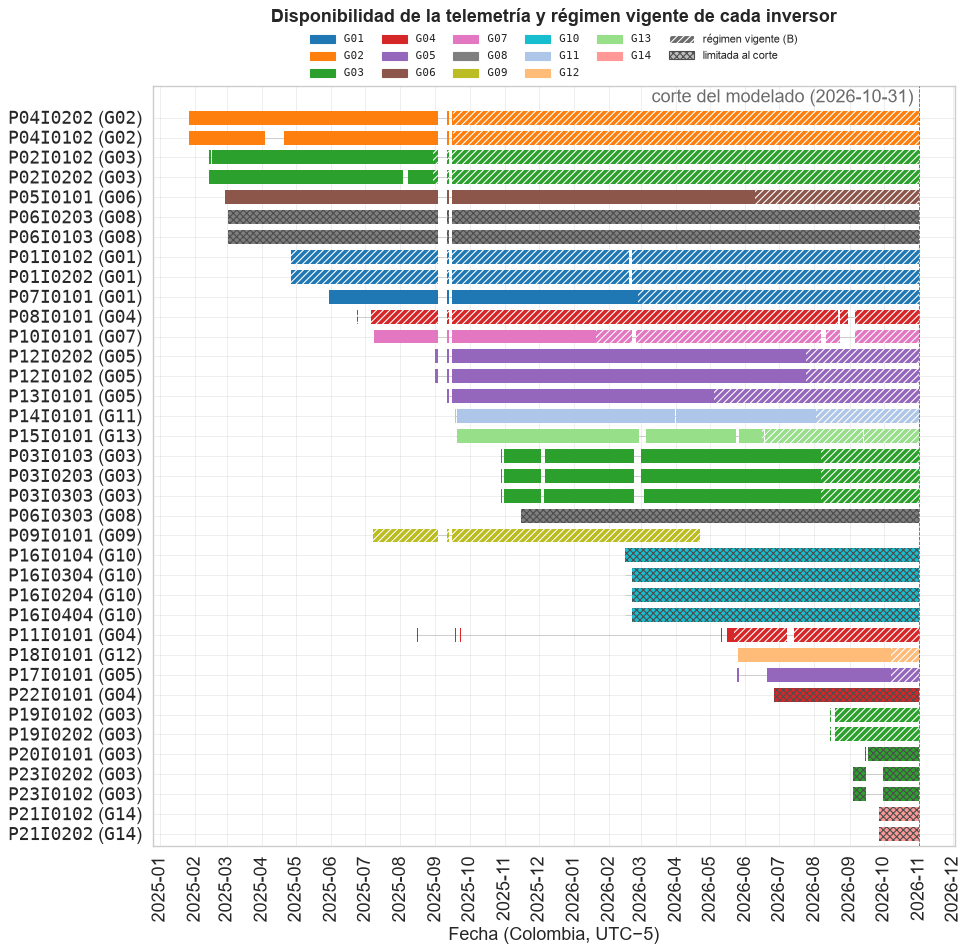

,grupo,dias_con_datos,inicio_regimen_b,limitada_al_corte,origen_estado
codigo,,,,,
P04I0202,G02,632,2025-09-17,False,telemetria
P04I0102,G02,615,2025-09-17,False,telemetria
P02I0102,G03,613,2025-08-30,False,telemetria
P02I0202,G03,610,2025-08-30,False,telemetria
P05I0101,G06,600,2026-06-10,False,telemetria
P06I0203,G08,598,NaN,True,instalador
P06I0103,G08,598,NaN,True,instalador
P01I0102,G01,540,2025-04-01,False,telemetria
P01I0202,G01,540,2025-04-01,False,telemetria


In [11]:
import matplotlib.dates as mdates
from matplotlib.patches import Patch
LECTURAS_MIN_DIA = 12            # un día cuenta con datos si tiene al menos una hora de lecturas de 5 min
fin_d = pd.Timestamp(config.FIN_MODELADO)
loc_r = res.cargar().get("localidades", {})
per = {n: v for g_ in loc_r.values() for n, v in g_.get("datos", {}).get("periodo_modelado", {}).items()}
filas_c = []
for g in sorted(FLOTA["grupo"].unique()):
    for s in datos.series_localidad(g, meteo=False, ideam=False):
        if not s.nombre.startswith("inv_"):
            continue
        codigo = s.filtros.get("dispositivo") or nom.inversor(s.filtros["deviceuuid"])
        if codigo[:3] not in FLOTA.index:
            continue
        d = datos.leer_serie(s, config.INICIO_DATOS, config.FIN_MODELADO)
        dia = d["datatime"].dt.tz_convert(config.ZONA).dt.tz_localize(None).dt.normalize()
        for dd, n in dia.value_counts().items():
            filas_c.append({"codigo": codigo, "grupo": g, "dia": dd, "lecturas": int(n)})
C = pd.DataFrame(filas_c)
C["con_datos"] = C["lecturas"] >= LECTURAS_MIN_DIA
DISP = (C.groupby(["codigo", "grupo"]).agg(primer_dia=("dia", "min"), ultimo_dia=("dia", "max"), dias_con_datos=("con_datos", "sum"))
         .reset_index().sort_values("dias_con_datos", ascending=False).reset_index(drop=True))
paleta = plt.get_cmap("tab20")
orden_c = [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19]
COLOR_G = {gg: paleta(orden_c[i % 20]) for i, gg in enumerate(sorted(DISP["grupo"].unique()))}
f, ax = plt.subplots(figsize=(12, 0.26 * len(DISP) + 2.2))
filas_f = []
for i, r in DISP.iterrows():
    d = C[(C["codigo"] == r["codigo"]) & C["con_datos"]].sort_values("dia")["dia"]
    ax.hlines(i, mdates.date2num(r["primer_dia"]), mdates.date2num(r["ultimo_dia"]) + 1, color="#BDBDBD", lw=0.6, zorder=1)
    corte_t = (d.diff() != pd.Timedelta(days=1)).cumsum()
    tramos = [(mdates.date2num(s_.iloc[0]), len(s_)) for _, s_ in d.groupby(corte_t)]
    col = COLOR_G[r["grupo"]]
    ax.broken_barh(tramos, (i - 0.35, 0.7), facecolors=col, lw=0, zorder=2)
    reg_ = REG.get(r["codigo"][:3], {})
    limitada = reg_.get("estado") == "limitada al corte"
    ini = None if limitada else (pd.Timestamp(per[r["codigo"]]["desde"]) if per.get(r["codigo"], {}).get("desde") else None)
    if limitada:
        tramo_r = tramos
    elif ini is not None and ini < fin_d:
        x0, x1 = mdates.date2num(max(ini, r["primer_dia"])), mdates.date2num(fin_d)
        tramo_r = [(max(a, x0), min(a + n, x1) - max(a, x0)) for a, n in tramos if min(a + n, x1) > max(a, x0)]
    else:
        tramo_r = []
    # Rayado blanco con borde: se ve igual sobre los colores claros y los oscuros
    if tramo_r:
        ax.broken_barh(tramo_r, (i - 0.35, 0.7), facecolors="none", edgecolors="white" if not limitada else "#4D4D4D",
                       hatch="xxxx" if limitada else "////", lw=0.0, zorder=3)
    filas_f.append({"codigo": r["codigo"], "grupo": r["grupo"], "dias_con_datos": int(r["dias_con_datos"]),
                    "inicio_regimen_b": None if ini is None else str(ini.date()), "limitada_al_corte": limitada,
                    "origen_estado": reg_.get("origen")})
x = mdates.date2num(fin_d)
ax.axvline(x, color=config.COLOR_NEUTRO, ls="--", lw=0.8, zorder=4)
ax.annotate(f"corte del modelado ({fin_d - pd.Timedelta(days=1):%Y-%m-%d}) ", (x, -1.0), ha="right", va="center", color=config.COLOR_NEUTRO)
ax.set_yticks(range(len(DISP)), [f"{r.codigo} ({r.grupo})" for r in DISP.itertuples()])
ax.set_ylim(len(DISP) - 0.4, -1.6)
ax.xaxis_date()
ax.set_xlabel("Fecha (Colombia, UTC−5)")
ax.set_title("Disponibilidad de la telemetría y régimen vigente de cada inversor")
manijas = ([Patch(color=COLOR_G[gg], label=gg) for gg in COLOR_G]
           + [Patch(facecolor="#6B6B6B", edgecolor="white", hatch="////", label="régimen vigente (B)"),
              Patch(facecolor="#BDBDBD", edgecolor="#4D4D4D", hatch="xxxx", label="limitada al corte")])
ax.legend(handles=manijas, ncols=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
TAB_DISP = pd.DataFrame(filas_f).set_index("codigo")
fig(f, "disponibilidad_regimen", TAB_DISP)
display(TAB_DISP)

## 8. Registro de resultados

Se registran en `resultados.json` el estado de cada planta al corte, el inicio del régimen B, la regla de tensión
calibrada y, si se calculó, el costo de no depurar.

In [12]:
def limpio(v):
    if isinstance(v, (pd.Timestamp,)):
        return str(v.date())
    if isinstance(v, (np.floating, float)):
        return None if not np.isfinite(v) else float(v)
    if isinstance(v, (np.integer,)):
        return int(v)
    return v
# Resumen para el documento: plantas por estado al corte, firma mediana de los inversores con sensor y costo de no
# depurar en las unidades que se pueden evaluar con A y con B (mismas horas de prueba)
ambos = ABLA.dropna(subset=["nrmse_A", "nrmse_B"]) if len(ABLA) else pd.DataFrame(columns=["nrmse_A", "nrmse_B"])
dif_ab = ambos["nrmse_A"] - ambos["nrmse_B"]
RESUMEN_FLOTA = {
    "plantas": int(len(RESUMEN)), "plantas_por_estado": {k: int(v) for k, v in RESUMEN["estado"].value_counts().items()},
    "plantas_con_sensor": int((RESUMEN["estado"] != "sin sensor").sum()),
    "firma_mediana": FIRMA[["p_rel_en_cero", "p_rel_libre", "v_rel_en_cero", "v_rel_libre"]].median().round(4).to_dict() if len(FIRMA) else {},
    "inversores_firma": int(len(FIRMA)),
    # Limitación parcial dentro del régimen B (horas sueltas recortadas después del último día limitado)
    "horas_produccion_b": int(RESUMEN["horas_produccion_b"].sum()),
    "horas_recortadas_b": int(RESUMEN["horas_recortadas_b"].sum()),
    "pct_recortadas_b": float(100 * RESUMEN["horas_recortadas_b"].sum() / max(RESUMEN["horas_produccion_b"].sum(), 1)),
    "pct_recortadas_b_max": float((100 * RESUMEN["horas_recortadas_b"] / RESUMEN["horas_produccion_b"]).max()),
    "planta_pct_recortadas_b_max": str((RESUMEN["horas_recortadas_b"] / RESUMEN["horas_produccion_b"]).idxmax()),
    # Horas marcadas dentro de B: coincidencia (producción típica) o recorte (producción reducida)
    **COINCIDENCIA,
    "ablacion_unidades": int(len(ambos)),
    "ablacion_mediana_a_menos_b": float(dif_ab.median()) if len(dif_ab) else None,
    "ablacion_max_a_menos_b": float(dif_ab.max()) if len(dif_ab) else None,
    "ablacion_b_mejor": int((dif_ab > 0.5).sum()), "ablacion_a_mejor": int((dif_ab < -0.5).sum()),
    # Diferencias significativas con Diebold-Mariano diario y Holm (p < 0,05)
    "ablacion_significativas": int((ambos.get("p_dm_holm", pd.Series(dtype=float)) < 0.05).sum()),
    "ablacion_b_mejor_significativa": int(((ambos.get("p_dm_holm", pd.Series(dtype=float)) < 0.05) & (dif_ab > 0)).sum()),
    "ablacion_a_mejor_significativa": int(((ambos.get("p_dm_holm", pd.Series(dtype=float)) < 0.05) & (dif_ab < 0)).sum()),
    # Pregunta de la flota: Wilcoxon unilateral (A peor que B) sobre las diferencias no nulas
    "ablacion_wilcoxon_a_p": wilcoxon_peor(dif_ab)[0] if len(dif_ab) else None,
    "ablacion_wilcoxon_a_n": wilcoxon_peor(dif_ab)[1] if len(dif_ab) else 0,
    "ablacion_mediana_nmbe_a": float(ambos["nmbe_A"].median()) if "nmbe_A" in ambos and len(ambos) else None,
    "ablacion_mediana_nmbe_b": float(ambos["nmbe_B"].median()) if "nmbe_B" in ambos and len(ambos) else None,
    # Todo el histórico (T) frente a B
    **({} if "nrmse_T" not in ABLA else (lambda t_: {
        "ablacion_t_unidades": int(len(t_)),
        "ablacion_mediana_t_menos_b": float((t_["nrmse_T"] - t_["nrmse_B"]).median()) if len(t_) else None,
        "ablacion_max_t_menos_b": float((t_["nrmse_T"] - t_["nrmse_B"]).max()) if len(t_) else None,
        "ablacion_t_peor_significativa": int(((t_.get("p_dm_t_holm", pd.Series(np.nan, index=t_.index)) < 0.05) & (t_["nrmse_T"] > t_["nrmse_B"])).sum()),
        "ablacion_t_mejor_significativa": int(((t_.get("p_dm_t_holm", pd.Series(np.nan, index=t_.index)) < 0.05) & (t_["nrmse_T"] < t_["nrmse_B"])).sum()),
        "ablacion_t_peor": int((t_["nrmse_T"] - t_["nrmse_B"] > 0.005).sum()),
        "ablacion_wilcoxon_t_p": wilcoxon_peor(t_["nrmse_T"] - t_["nrmse_B"])[0],
        "ablacion_wilcoxon_t_n": wilcoxon_peor(t_["nrmse_T"] - t_["nrmse_B"])[1],
        "ablacion_mediana_nmbe_t": float(t_["nmbe_T"].median()) if "nmbe_T" in t_ and len(t_) else None})(
        ABLA.dropna(subset=["nrmse_T", "nrmse_B"])))}
display(pd.Series(RESUMEN_FLOTA, dtype=object).to_frame("valor"))
res.registrar("flota.recorte", {
    "corte": config.FIN_MODELADO,
    "plantas": {p: {k: limpio(v) for k, v in fila.items()} for p, fila in RESUMEN.to_dict(orient="index").items()},
    "firma": FIRMA.round(4).to_dict(orient="index") if len(FIRMA) else {},
    "regla_tension": {**PARAM, "f1_calibracion": float(MEJOR.f1), "precision_calibracion": float(MEJOR.precision),
                      "exhaustividad_calibracion": float(MEJOR.exhaustividad), "f1_fuera": float(fuera.f1),
                      "precision_fuera": float(fuera.precision), "exhaustividad_fuera": float(fuera.exhaustividad)},
    "ablacion": ABLA.round(3).replace({np.nan: None}).to_dict(orient="index") if len(ABLA) else {},
    "resumen": RESUMEN_FLOTA})
display(Markdown("Resultados registrados en `flota.recorte`."))

,valor
plantas,23
plantas_por_estado,"{'liberada': 10, 'limitada al corte': 6, 'nunc..."
plantas_con_sensor,22
firma_mediana,"{'p_rel_en_cero': 0.3069, 'p_rel_libre': 0.699..."
inversores_firma,24
horas_produccion_b,31171
horas_recortadas_b,516
pct_recortadas_b,1.655385
pct_recortadas_b_max,4.881603
planta_pct_recortadas_b_max,P07


Resultados registrados en `flota.recorte`.